<div style="background: linear-gradient(135deg, #114F6A 0%, #1FA4B1 100%); padding: 28px; border-radius: 12px; color: #FFFFFF; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 12px rgba(17, 79, 106, 0.2);">
  <h1 style="margin: 0; font-size: 26px; letter-spacing: 1px; color: #FFFFFF;">PROYEK UTS PRAKTIKUM DEEP LEARNING</h1>
  <p style="margin: 6px 0 20px 0; font-size: 14px; color: #E0F7FA; opacity: 0.95;">Implementasi Sequence Deep Learning (RNN / LSTM) untuk Analisis Sentimen & Time-Series Forecasting</p>
  
  <div style="background-color: #FFFFFF; color: #1E293B; padding: 18px 22px; border-radius: 8px; border-left: 6px solid #114F6A;">
    <h3 style="margin: 0 0 12px 0; color: #114F6A; font-size: 16px; border-bottom: 2px solid #E2E8F0; padding-bottom: 6px;">DATA DIRI & KONFIGURASI PROYEK</h3>
    <table style="width: 100%; border-collapse: collapse; font-size: 14px; color: #1E293B;">
      <tr>
        <td style="padding: 6px 0; width: 220px; font-weight: bold; color: #114F6A;">Nama Lengkap</td>
        <td style="padding: 6px 0;">: Sindi Evelin Sembiring</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">NIM</td>
        <td style="padding: 6px 0;">: 202432099</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kelas</td>
        <td style="padding: 6px 0;">: C</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kategori Tugas (Sesuai NIM)</td>
        <td style="padding: 6px 0;">: Analisis Sentimen NLP (NIM Ganjil)</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Algoritma yang Dipilih</td>
        <td style="padding: 6px 0;">: <span style="background-color: #1FA4B1; color: #FFFFFF; padding: 2px 10px; border-radius: 4px; font-weight: bold;">LSTM</span></td>
      </tr>
    </table>
  </div>
</div>

#

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 12px;">
  <div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 16px; border-bottom: 4px solid #1FA4B1;">
    BAB 1 — LATAR BELAKANG MASALAH
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 20px; line-height: 1.7; font-size: 14px;">
    <p style="margin-top: 0;">
      <b>1. Deskripsi Permasalahan:</b><br>
      Belanja online di Indonesia menghasilkan ulasan produk dalam jumlah sangat besar, dan isinya ditulis bebas (informal, banyak singkatan). Kalau dibaca satu per satu, penjual dan platform sulit mengetahui pembeli mana yang puas dan mana yang kecewa. Analisis sentimen otomatis membantu mengelompokkan ulasan menjadi positif atau negatif dengan cepat, sehingga keluhan utama bisa segera ditangani. Teks adalah data sekuensial: urutan kata memengaruhi makna (misalnya &quot;tidak bagus&quot; berlawanan dengan &quot;bagus&quot;), sehingga cocok dianalisis dengan Deep Learning berbasis sekuens.
    </p>
    <p style="margin-bottom: 0;">
      <b>2. Tujuan Pemodelan & Alasan Pemilihan Algoritma:</b><br>
      <b>Tujuan:</b> (1) membangun model yang mengklasifikasikan ulasan produk Lazada menjadi sentimen positif atau negatif, (2) memahami alur komputasi internal LSTM lewat perhitungan manual, dan (3) mengevaluasi performa model melalui grafik. <b>Alasan memilih LSTM:</b> LSTM adalah varian RNN yang memakai gerbang (forget, input, output) dan cell state untuk menjaga informasi jangka panjang, sehingga mengurangi masalah vanishing gradient dan lebih baik daripada RNN standar untuk kalimat yang panjang.
    </p>
  </div>
</div>

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: sans-serif; margin-top: 10px;">
<div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 15px; border-bottom: 4px solid #1FA4B1;">INFORMASI &amp; KARAKTERISTIK DATASET KAGGLE</div>
<div style="background-color: #F8FAFC; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
<div style="background-color: #E0F7FA; border-left: 5px solid #1FA4B1; padding: 12px 16px; border-radius: 4px; margin-bottom: 14px;">
<b style="color: #114F6A;">Nama Dataset:</b> Lazada Indonesian Reviews (penulis: grikomsn)<br>
<b style="color: #114F6A;">Link Dataset Kaggle:</b> <a href="https://www.kaggle.com/datasets/grikomsn/lazada-indonesian-reviews" target="_blank" style="color: #114F6A; font-weight: bold; text-decoration: underline;">https://www.kaggle.com/datasets/grikomsn/lazada-indonesian-reviews</a>
</div>
<div style="margin-bottom: 12px;">
<b style="color: #114F6A;">Penjelasan Umum Dataset:</b><br>
Dataset berisi ulasan produk dari Lazada Indonesia per kategori produk (lisensi CC0-1.0). File yang dipakai adalah <code>20191002-reviews.csv</code> dengan <b>203.787 baris</b> dan <b>15 kolom</b>. Dua kolom yang dipakai: <code>reviewContent</code> (teks ulasan, sebagai fitur) dan <code>rating</code> (bintang 1-5, sebagai dasar label). Dari seluruh baris, 107.029 ulasan memiliki teks dan rating. Pelabelan: rating 4-5 = positif (1), rating 1-2 = negatif (0), rating 3 dibuang. Kelas diseimbangkan dengan undersampling (9.135 ulasan per kelas).
</div>
</div>
</div>

#

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">1. IMPORT LIBRARY</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.</p>
</div>

In [14]:
#202432099_SindiESembiring
import os, re, glob, copy, random, zipfile
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device:', device)

PyTorch: 2.14.1+cpu | Device: cpu


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">2. PRA-PEMROSESAN DATA (PREPROCESSING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.</p>
</div>

In [15]:
##202432099_SindiESembiring
# 1. Muat dataset Kaggle (Lazada Indonesian Reviews). File zip dataset ada di repositori GitHub,
#    jadi tidak perlu token Kaggle. Alternatif: unggah zip secara manual ke panel Files Colab.
ZIP_URL = 'https://github.com/sindisembiring/uts-deeplearning/raw/main/lazada-indonesian-reviews.zip'
ZIP_FILE = 'lazada-indonesian-reviews.zip'
if not glob.glob('data_lazada/*reviews*.csv'):
    if not os.path.exists(ZIP_FILE) or os.path.getsize(ZIP_FILE) == 0:
        os.system(f'wget -q -O {ZIP_FILE} "{ZIP_URL}"')
    if not os.path.exists(ZIP_FILE) or os.path.getsize(ZIP_FILE) == 0:
        raise FileNotFoundError('Zip dataset tidak ditemukan. Cek ZIP_URL atau unggah lazada-indonesian-reviews.zip ke panel Files Colab.')
    with zipfile.ZipFile(ZIP_FILE) as z:
        z.extractall('data_lazada')
path = glob.glob('data_lazada/*reviews*.csv')[0]
df = pd.read_csv(path)
print('Jumlah baris & kolom:', df.shape)
print(df.columns.tolist())
TEXT_COL = [c for c in df.columns if c.lower() in ('reviewcontent', 'review', 'content', 'text')][0]
RATING_COL = [c for c in df.columns if c.lower() == 'rating'][0]
df = df[[TEXT_COL, RATING_COL]].dropna()
df.columns = ['text', 'rating']
print('Jumlah ulasan per rating:'); print(df['rating'].value_counts().sort_index())

# 2. Pembersihan data & pra-pemrosesan (NIM ganjil / NLP)
#    Pelabelan: rating 4-5 = positif (1), rating 1-2 = negatif (0), rating 3 dibuang
df = df[df['rating'] != 3].copy()
df['label'] = (df['rating'] >= 4).astype(int)
n_per_class = min(df['label'].value_counts().min(), 10000)
df = pd.concat([df[df['label'] == k].sample(n_per_class, random_state=SEED) for k in (0, 1)])
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
print('Jumlah data per kelas setelah seimbang:'); print(df['label'].value_counts())

#    Case folding & pembersihan teks
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\S+', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    t = re.sub(r'(.)\1{2,}', r'\1', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t
df['clean'] = df['text'].apply(clean_text)
df = df[df['clean'].str.split().str.len() >= 2].reset_index(drop=True)
display(df[['text', 'clean', 'label']].head())

#    Pembagian data 70% latih, 15% validasi, 15% uji
tr_text, tmp_text, tr_y, tmp_y = train_test_split(df['clean'], df['label'], test_size=0.3, stratify=df['label'], random_state=SEED)
va_text, te_text, va_y, te_y = train_test_split(tmp_text, tmp_y, test_size=0.5, stratify=tmp_y, random_state=SEED)
print('Data latih / validasi / uji:', len(tr_text), len(va_text), len(te_text))

#    Tokenisasi + vocabulary mapping (dari data latih saja) + padding
VOCAB_SIZE = 10000
MAX_LEN = 60
counter = Counter(w for t in tr_text for w in t.split())
itos = ['<PAD>', '<UNK>'] + [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}

def encode(text):
    ids = [stoi.get(w, 1) for w in text.split()][:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))

def to_tensor(texts):
    return torch.tensor([encode(t) for t in texts], dtype=torch.long)

# 3. Konversi data menjadi PyTorch Tensor dan DataLoader
X_train, y_train = to_tensor(tr_text), torch.tensor(tr_y.values, dtype=torch.float32)
X_val, y_val = to_tensor(va_text), torch.tensor(va_y.values, dtype=torch.float32)
X_test, y_test = to_tensor(te_text), torch.tensor(te_y.values, dtype=torch.float32)
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print('Bentuk X_train:', tuple(X_train.shape), '| Bentuk y_train:', tuple(y_train.shape))

Jumlah baris & kolom: (203787, 15)
['itemId', 'category', 'name', 'rating', 'originalRating', 'reviewTitle', 'reviewContent', 'likeCount', 'upVotes', 'downVotes', 'helpful', 'relevanceScore', 'boughtDate', 'clientType', 'retrievedDate']
Jumlah ulasan per rating:
rating
1     6951
2     2184
3     4372
4    10626
5    82896
Name: count, dtype: int64
Jumlah data per kelas setelah seimbang:
label
0    9135
1    9135
Name: count, dtype: int64


,text,clean,label
0,Kecepatan pengiriman Oke .. cuman Packing kayu...,kecepatan pengiriman oke cuman packing kayu ny...,0
1,Masih yakin mau beli?? buang2 duit gan..,masih yakin mau beli buang duit gan,0
2,"Pesannya yg warna hitam, tapi dateng nya malah...",pesannya yg warna hitam tapi dateng nya malah ...,0
3,"Flashdisknya ga bisa dipake, pas mau masukin d...",flashdisknya ga bisa dipake pas mau masukin da...,0
4,"Laptop berfungsi baik , screen non glare ok , ...",laptop berfungsi baik screen non glare ok cpu ...,1


Data latih / validasi / uji: 12169 2608 2608
Bentuk X_train: (12169, 60) | Bentuk y_train: (12169,)


In [16]:
print('Dataset lokal Anda telah berhasil dimuat dan siap digunakan!')
print('File path:', path)
print('Ukuran DataFrame saat ini:', df.shape)

Dataset lokal Anda telah berhasil dimuat dan siap digunakan!
File path: data_lazada/20191002-reviews.csv
Ukuran DataFrame saat ini: (17385, 4)


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">3. PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.</p>
</div>

In [17]:
#202432099_SindiESembiring
class SequenceModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_size):
        super(SequenceModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_size, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc1 = nn.Linear(hidden_size, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()          # panjang asli tiap ulasan (tanpa padding)
        emb = self.embedding(x)                                    # (batch, 60, embed_dim)
        packed = pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)                            # h_n = hidden state terakhir tiap ulasan
        h = self.dropout(h_n[-1])
        return self.fc2(self.relu(self.fc1(h))).squeeze(1)         # logit sentimen (sigmoid dipakai saat prediksi)

# Verifikasi perhitungan manual BAB 2: nn.LSTM 1 unit dengan bobot yang sama dengan hitungan tangan
# (urutan gate PyTorch: input, forget, cell, output; bobot tiap gate = [bobot h_{t-1}, bobot x_t])
lstm_demo = nn.LSTM(input_size=1, hidden_size=1, batch_first=True)
with torch.no_grad():
    lstm_demo.weight_ih_l0.copy_(torch.tensor([[0.6], [0.4], [0.2], [0.5]]))    # bobot x_t   : i, f, c, o
    lstm_demo.weight_hh_l0.copy_(torch.tensor([[0.3], [0.5], [0.7], [0.4]]))    # bobot h_t-1 : i, f, c, o
    lstm_demo.bias_ih_l0.copy_(torch.tensor([0.0, 0.1, 0.1, 0.05]))             # bias        : i, f, c, o
    lstm_demo.bias_hh_l0.zero_()
    x_t = torch.tensor([[[0.5]]]); h_prev = torch.tensor([[[0.1]]]); C_prev = torch.tensor([[[0.2]]])
    _, (h_t, C_t) = lstm_demo(x_t, (h_prev, C_prev))
print(f'nn.LSTM PyTorch -> h_t = {h_t.item():.4f} | C_t = {C_t.item():.4f}')
print('Hitungan manual  -> h_t = 0.1544 | C_t = 0.2707')

nn.LSTM PyTorch -> h_t = 0.1544 | C_t = 0.2707
Hitungan manual  -> h_t = 0.1544 | C_t = 0.2707


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">4. INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.</p>
</div>

In [18]:
#202432099_SindiESembiring
# 1. Inisiasi hyperparameter
epochs = 10
learning_rate = 0.001
embed_dim = 64
hidden_size = 64
patience = 2          # early stopping: berhenti jika val_loss tidak membaik selama 2 epoch

# 2. Inisiasi model, fungsi Loss, dan Optimizer
model = SequenceModel(VOCAB_SIZE, embed_dim, hidden_size).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
print(model)
print('Total parameter:', sum(p.numel() for p in model.parameters()))

# 3. Simpan riwayat nilai loss dan akurasi untuk divisualisasikan
train_losses, val_losses, train_accs, val_accs = [], [], [], []

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

# 4. Training loop
best_val_loss, best_state, wait = float('inf'), None, 0
for epoch in range(1, epochs + 1):
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    train_losses.append(tl); val_losses.append(vl); train_accs.append(ta); val_accs.append(va)
    print(f'Epoch {epoch:02d}/{epochs} | loss {tl:.4f} acc {ta:.4f} | val_loss {vl:.4f} val_acc {va:.4f}')
    if vl < best_val_loss:
        best_val_loss, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= patience:
            print(f'Early stopping di epoch {epoch}. Bobot terbaik (val_loss = {best_val_loss:.4f}) dikembalikan.')
            break
model.load_state_dict(best_state)

SequenceModel(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)
Total parameter: 675393
Epoch 01/10 | loss 0.4883 acc 0.7697 | val_loss 0.3667 val_acc 0.8524
Epoch 02/10 | loss 0.2940 acc 0.8910 | val_loss 0.3211 val_acc 0.8754
Epoch 03/10 | loss 0.2265 acc 0.9237 | val_loss 0.2764 val_acc 0.8957
Epoch 04/10 | loss 0.1799 acc 0.9435 | val_loss 0.2712 val_acc 0.9030
Epoch 05/10 | loss 0.1500 acc 0.9548 | val_loss 0.2486 val_acc 0.9168
Epoch 06/10 | loss 0.1222 acc 0.9639 | val_loss 0.2735 val_acc 0.9099
Epoch 07/10 | loss 0.0998 acc 0.9712 | val_loss 0.2804 val_acc 0.9133
Early stopping di epoch 7. Bobot terbaik (val_loss = 0.2486) dikembalikan.


<All keys matched successfully>

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">5. VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.</p>
</div>

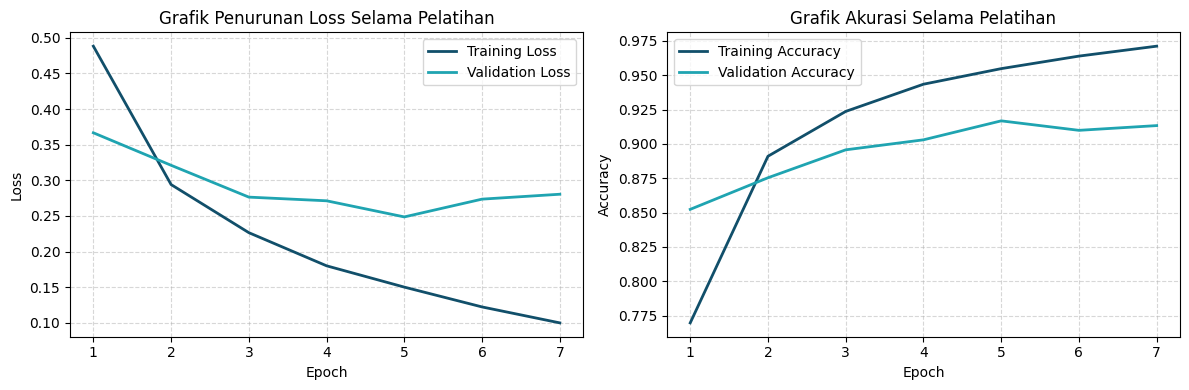

Test Accuracy: 0.9252
              precision    recall  f1-score   support

     Negatif       0.91      0.94      0.93      1345
     Positif       0.94      0.90      0.92      1263

    accuracy                           0.93      2608
   macro avg       0.93      0.92      0.93      2608
weighted avg       0.93      0.93      0.93      2608



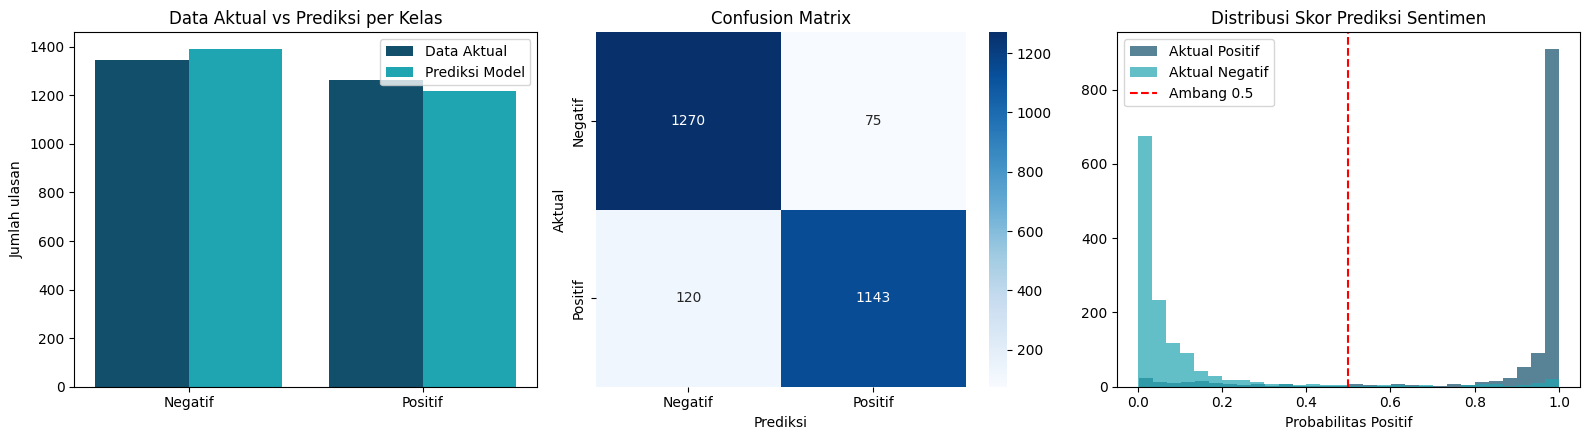

0.999 -> Positif | barang bagus sesuai deskripsi pengiriman cepat
0.011 -> Negatif | kecewa barang rusak dan tidak sesuai pesanan


In [19]:
#202432099_SindiESembiring
# 1. Plot Grafik Penurunan Loss Training terhadap Epoch (dan akurasi)
epoch_axis = range(1, len(train_losses) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epoch_axis, train_losses, color='#114F6A', linewidth=2, label='Training Loss')
plt.plot(epoch_axis, val_losses, color='#1FA4B1', linewidth=2, label='Validation Loss')
plt.title('Grafik Penurunan Loss Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(epoch_axis, train_accs, color='#114F6A', linewidth=2, label='Training Accuracy')
plt.plot(epoch_axis, val_accs, color='#1FA4B1', linewidth=2, label='Validation Accuracy')
plt.title('Grafik Akurasi Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Evaluasi data uji dan perbandingan Data Aktual vs Hasil Prediksi Model
model.eval()
with torch.no_grad():
    probs = torch.cat([torch.sigmoid(model(xb.to(device))).cpu() for xb, _ in test_loader]).numpy()
y_true = y_test.numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)
print(f'Test Accuracy: {(y_pred == y_true).mean():.4f}')
print(classification_report(y_true, y_pred, target_names=['Negatif', 'Positif']))

plt.figure(figsize=(16, 4.5))
plt.subplot(1, 3, 1)      # jumlah data aktual vs prediksi per kelas
idx = np.arange(2)
plt.bar(idx - 0.2, np.bincount(y_true, minlength=2), width=0.4, color='#114F6A', label='Data Aktual')
plt.bar(idx + 0.2, np.bincount(y_pred, minlength=2), width=0.4, color='#1FA4B1', label='Prediksi Model')
plt.xticks(idx, ['Negatif', 'Positif']); plt.ylabel('Jumlah ulasan')
plt.title('Data Aktual vs Prediksi per Kelas'); plt.legend()
plt.subplot(1, 3, 2)      # confusion matrix
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif', 'Positif'], yticklabels=['Negatif', 'Positif'])
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion Matrix')
plt.subplot(1, 3, 3)      # distribusi skor prediksi sentimen
plt.hist(probs[y_true == 1], bins=30, alpha=0.7, color='#114F6A', label='Aktual Positif')
plt.hist(probs[y_true == 0], bins=30, alpha=0.7, color='#1FA4B1', label='Aktual Negatif')
plt.axvline(0.5, color='red', linestyle='--', label='Ambang 0.5')
plt.xlabel('Probabilitas Positif'); plt.title('Distribusi Skor Prediksi Sentimen'); plt.legend()
plt.tight_layout()
plt.show()

# 3. Contoh prediksi kalimat baru
contoh = ['barang bagus sesuai deskripsi pengiriman cepat', 'kecewa barang rusak dan tidak sesuai pesanan']
with torch.no_grad():
    skor = torch.sigmoid(model(to_tensor([clean_text(c) for c in contoh]).to(device))).cpu().numpy()
for c, s in zip(contoh, skor):
    print(f'{s:.3f} -> {"Positif" if s >= 0.5 else "Negatif"} | {c}')

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <div style="background-color: #1FA4B1; color: #FFFFFF; padding: 10px 20px; font-weight: bold; font-size: 15px;">
    RINGKASAN ANALISIS PERFORMA MODEL
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
    <p style="margin: 0;">
      <b>Kesimpulan Hasil Visualisasi:</b><br>
      [ISI SETELAH NOTEBOOK DIJALANKAN: tren kurva loss per epoch, akurasi uji, dan seberapa baik prediksi model pada grafik di atas.]
    </p>
  </div>
</div>